# 05 · Feature Engineering (day-ahead, leakage-safe)
**Setting:** each morning NLDC schedules generation for **tomorrow (day D)**. It knows demand up to D-1 and has a
weather forecast for D. Our features follow that: load information from **D-1 and earlier**, weather for **D**
(observed weather as a perfect-forecast proxy, the standard ex-post set-up).

### Target transform: `z = 100 * (peak_D / mean(peak_{D-1..D-7}) - 1)`
Trees cannot extrapolate: each leaf predicts an average of *training* targets. Trained on 2019-2023 MW (max ~237 GW),
a tree model can never output 2025's 240+ GW, so it would **systematically under-forecast**, the most dangerous error.
`z` ("% above last week") is stationary, and the MW forecast is `base * (1 + z/100)`.

In [1]:
# --- common setup ------------------------------------------------------------
# The project code lives in src/heatwave_peak (installed with `pip install -e .`).
# If it is not installed, fall back to adding src/ to the import path.
import sys, warnings
from pathlib import Path
try:
    import heatwave_peak
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import heatwave_peak
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from heatwave_peak import config as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    """Save the current figure to reports/figures/<name>.png."""
    plt.savefig(C.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

In [2]:
from heatwave_peak import features as F, clustering as CL, heatwave as HW, load_processing as LP
sw = pd.read_parquet(C.INTERIM_DIR / "state_daily_weather_1991_2025.parquet")
sw = sw[(sw.date >= "2018-12-01") & (sw.date <= C.STUDY_END)]
w = pd.read_csv(C.PROCESSED_DIR / "state_demand_weights.csv", index_col=0)["demand_weight"]
zones = pd.read_csv(C.PROCESSED_DIR / "state_signatures_and_zones.csv", index_col=0)
names = zones.drop_duplicates("zone_id").set_index("zone_id")["zone"].to_dict()
national_heat = HW.national_heat_exposure(sw, w)
zone_wide = CL.zone_daily_features(sw, zones["zone_id"], w, names)
nat_w = CL.zone_daily_features(sw, pd.Series(0, index=zones.index), w, {0: "IN"})
nat_w = nat_w.drop(columns=[c for c in nat_w.columns if c.endswith("heat_exposure")])
daily = pd.read_parquet(C.PROCESSED_DIR / "daily_peak_national.parquet")
tab = F.build_model_table(daily, national_heat, zone_wide, nat_w, LP.read_psp_daily())
feats = F.feature_columns(tab)
print("table:", tab.shape, "| features:", len(feats))

table: (2557, 318) | features: 309


## 1. Why the target transform is necessary

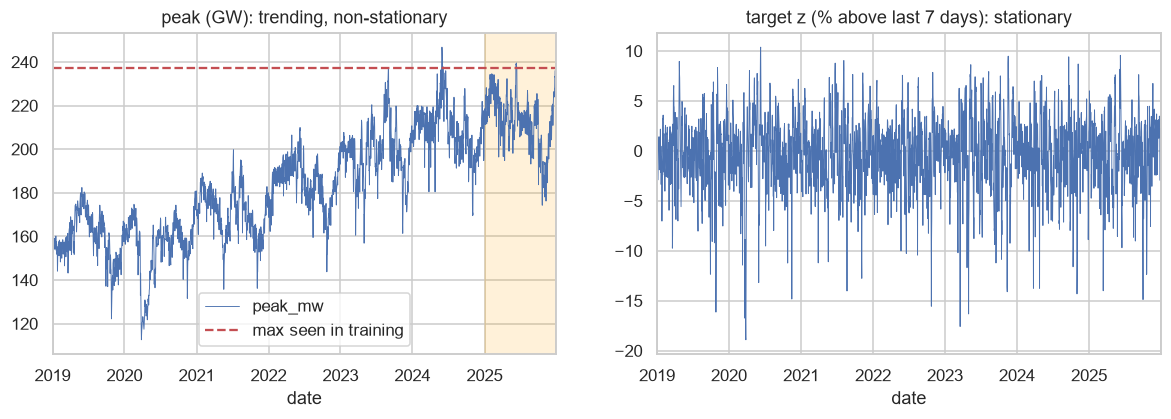

2024 days above the 2019-2023 maximum (237.4 GW): [datetime.date(2024, 5, 29), datetime.date(2024, 5, 30), datetime.date(2024, 5, 31), datetime.date(2024, 6, 1), datetime.date(2024, 6, 4)]
-> exactly the record-heatwave days: the most important days are the ones an MW-level tree model cannot reach.


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
tab.peak_mw.div(1e3).plot(ax=ax[0], lw=.6, title="peak (GW): trending, non-stationary")
ax[0].axvspan(C.TEST_START, C.TEST_END, color="orange", alpha=.15)
ax[0].axhline(tab.loc[:C.TRAIN_END, "peak_mw"].max() / 1e3, color="r", ls="--", label="max seen in training")
ax[0].legend()
tab.target_z.plot(ax=ax[1], lw=.6, title="target z (% above last 7 days): stationary")
savefig("05_target_transform"); plt.show()
tr_max = tab.loc[:C.TRAIN_END, "peak_mw"].max()
above = tab.loc[C.VALID_START:C.VALID_END].query("peak_mw > @tr_max")
print(f"2024 days above the 2019-2023 maximum ({tr_max/1e3:.1f} GW):", list(above.index.date))
print("-> exactly the record-heatwave days: the most important days are the ones an MW-level tree model cannot reach.")

## 2. Feature groups
| Group | Examples | Why |
|---|---|---|
| Load history (D-1 and earlier, % of base) | `peak_lag1_rel`, `peak_lag7_rel`, `peak_max7_rel`, `trend_1v7_pct`, `solar_peak_mw_lag1_rel`, `peak_hour_lag1` | demand is persistent; yesterday is the best single predictor |
| Calendar | `dow`, `is_sunday`, `doy_sin/cos`, `is_holiday`, `is_major_festival`, `major_festival_yesterday`, `diwali_window` | Sundays run ~5 % lower; Holi/Diwali -8..-11 %, with a +11 % rebound the day after |
| National heat | `heat_exposure`, `imd_hw_exposure`, `heat_severity_idx`, `warm_night_exposure`, `hot40_exposure` | the heatwave **regime** as an explicit input (gap G3) |
| Zone weather (x8 zones) | `Zx__imd_tmax`, `__imd_tmax_departure`, `__ehf`, `__heat_accum_ewm`, `__hot_day_run_length`, `__era5_heat_index_max`, `__era5_night_tmin`, `__era5_cdh24`, `__era5_precip_sum`, ... | regional contrast, heat accumulation and persistence (gap G7) |
| Weekly weather deltas | `...__d7` = weather(D) minus the mean of D-1..D-7 | matches the target: a *change* in heat versus last week drives a change in demand versus last week |
| Grid ops (D-1) | `share_res_pct_lag1`, `solar_gen_mu_lag1`, `energy_shortage_mu_lag1` | rising solar and recent shortages |

In [4]:
groups = {"load history": [f for f in feats if "lag" in f or f.startswith(("peak_", "trend", "yoy", "weekday", "load_factor"))],
          "calendar": [f for f in feats if f in ("dow","is_sunday","is_saturday","month","doy_sin","doy_cos","is_holiday","days_to_holiday",
                                                 "days_from_holiday","is_major_festival","major_festival_yesterday","diwali_window")],
          "national heat": [f for f in feats if f in ("imd_hw_exposure","heat_exposure","severe_exposure","heat_severity_idx","warm_night_exposure","hot40_exposure")],
          "national weather (IN__)": [f for f in feats if f.startswith("IN__") and not f.endswith("__d7")],
          "zone weather (Z*)": [f for f in feats if f.startswith("Z") and not f.endswith("__d7")],
          "weekly deltas (__d7)": [f for f in feats if f.endswith("__d7")]}
pd.Series({k: len(v) for k, v in groups.items()}, name="n_features")

load history                20
calendar                    12
national heat                6
national weather (IN__)     23
zone weather (Z*)          192
weekly deltas (__d7)        56
Name: n_features, dtype: int64

## 3. Does heat explain the target? (raw association before any modelling)

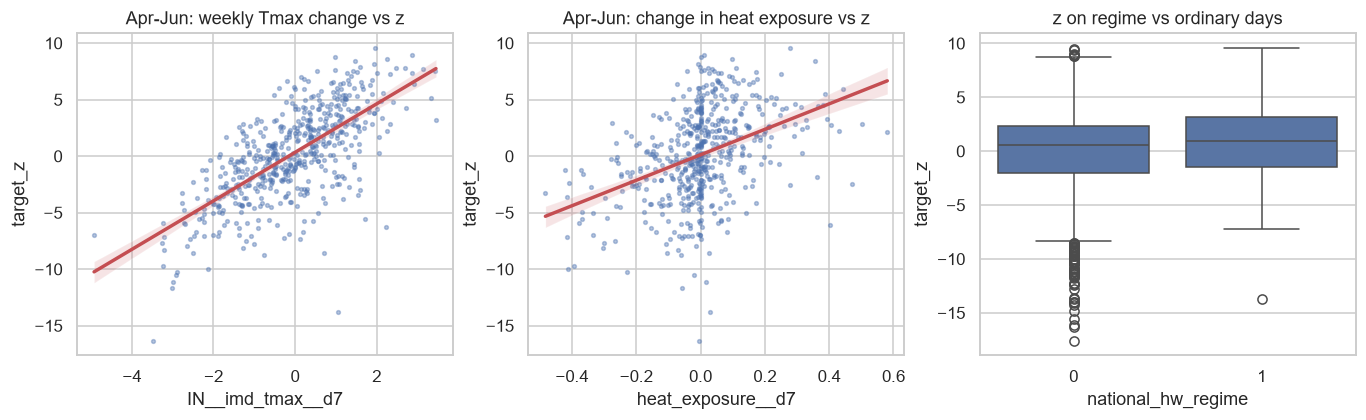

target_z                   1.000
IN__imd_tmax__d7           0.686
IN__era5_cdh24__d7         0.716
heat_exposure__d7          0.400
IN__era5_precip_sum__d7   -0.401
Name: target_z, dtype: float64


In [5]:
d = tab[(tab.train_weight > 0) & (tab.month.isin([4, 5, 6]))]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.regplot(data=d, x="IN__imd_tmax__d7", y="target_z", scatter_kws=dict(s=6, alpha=.4), ax=ax[0], line_kws=dict(color="r"))
sns.regplot(data=d, x="heat_exposure__d7", y="target_z", scatter_kws=dict(s=6, alpha=.4), ax=ax[1], line_kws=dict(color="r"))
sns.boxplot(data=tab[tab.train_weight > 0], x="national_hw_regime", y="target_z", ax=ax[2])
ax[0].set_title("Apr-Jun: weekly Tmax change vs z"); ax[1].set_title("Apr-Jun: change in heat exposure vs z"); ax[2].set_title("z on regime vs ordinary days")
savefig("05_heat_vs_target"); plt.show()
print(d[["target_z", "IN__imd_tmax__d7", "IN__era5_cdh24__d7", "heat_exposure__d7", "IN__era5_precip_sum__d7"]].corr()["target_z"].round(3))

## 4. Leakage audit
Every load feature must be computable at the end of D-1. Below we check that **no** feature is suspiciously correlated
with the target (|r| > 0.9 would hint that the target leaked in). We also confirm that the target is not among the features.

In [6]:
assert "target_z" not in feats and "peak_mw" not in feats and "is_critical_peak" not in feats
corr = tab.loc[tab.train_weight > 0, feats].corrwith(tab.loc[tab.train_weight > 0, "target_z"]).abs().sort_values(ascending=False)
print("max |corr(feature, target)| =", round(corr.max(), 3)); corr.head(10).round(3)

max |corr(feature, target)| = 0.604


peak_lag1_rel                             0.604
solar_peak_mw_lag1_rel                    0.497
IN__era5_cdh24__d7                        0.476
Z5_Uttar+Punjab__era5_cdh24__d7           0.445
IN__imd_tmax__d7                          0.430
Z0_Maharashtra+Gujarat__era5_cdh24__d7    0.424
is_sunday                                 0.419
Z5_Uttar+Punjab__imd_tmax__d7             0.404
trend_1v7_pct                             0.404
Z0_Maharashtra+Gujarat__imd_tmax__d7      0.388
dtype: float64

## 5. Weights, splits and save

In [7]:
print(tab.groupby("split").agg(days=("peak_mw", "size"), used_for_training=("train_weight", lambda x: int((x > 0).sum())),
                               heat_regime_days=("national_hw_regime", "sum"), critical_peak_days=("is_critical_peak", "sum")))
tab.to_parquet(C.PROCESSED_DIR / "model_table.parquet")

       days  used_for_training  heat_regime_days  critical_peak_days
split                                                               
test    365                355                14                  45
train  1826               1720               136                 357
valid   366                366                55                  60
